# 03 · Evaluación: horizonte de negocio, ablación de clima, SHAP y errores

Todas las cifras salen de `reports/` (generados por `python -m demanda_citibike.pipeline`):

* **Backtesting de origen móvil:** 4 semanas (5 nov – 3 dic), cada una pronosticada con un modelo entrenado solo con el pasado.
* **Test final:** 3–31 de diciembre de 2024 (28 días), nunca visto por ningún entrenamiento.
* Los tres modelos (día siguiente, día siguiente sin clima, 1 hora) usan exactamente los mismos cortes y las mismas filas.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from demanda_citibike.config import PROCESADOS, REPORTES, FIGURAS

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#333333"
res = json.loads((REPORTES / "resultados.json").read_text(encoding="utf-8"))

In [2]:
pred = pd.read_parquet(REPORTES / "predicciones_test.parquet")
cv = pd.read_parquet(REPORTES / "predicciones_cv.parquet")
nombres = {"pred_dia": "LightGBM día siguiente (principal)", "pred_dia_sin_clima": "LightGBM día siguiente sin clima",
           "pred_1h": "LightGBM 1 hora (comparación)", "base_estacional": "Base estacional t−168",
           "base_ayer": "Base ayer t−24", "base_media": "Base media móvil 3 h (solo a 1 h)"}
filas = []
for c, n in nombres.items():
    filas.append({"modelo": n, **{f"test_{k}": v for k, v in res["test_final"][c].items()},
                  "CV_WAPE_pct": res["backtesting_cv"][c]["WAPE_pct"]})
tabla = pd.DataFrame(filas).set_index("modelo")
tabla

,test_MAE,test_RMSE,test_WAPE_pct,test_Sesgo_pct,CV_WAPE_pct
modelo,,,,,
LightGBM día siguiente (principal),2.53,3.85,50.58,7.36,38.41
LightGBM día siguiente sin clima,2.91,4.31,58.21,22.61,45.21
LightGBM 1 hora (comparación),2.12,3.18,42.34,3.69,33.28
Base estacional t−168,3.64,5.80,72.86,7.37,54.42
Base ayer t−24,3.10,4.91,62.03,1.67,52.74
Base media móvil 3 h (solo a 1 h),3.03,4.74,60.60,0.25,55.38


## 1 · El resultado principal es el de horizonte de negocio

El modelo día siguiente es el que de verdad sirve para planificar el rebalanceo nocturno. Se compara con dos heurísticas que también estarían disponibles la noche anterior (misma hora de la semana pasada y misma hora de ayer).

In [3]:
m = res["mejoras_wape_pct"]
print(f"Día siguiente vs base estacional (test): {m['dia_vs_base_estacional_test']:+.1f} % de WAPE")
print(f"Día siguiente vs base ayer (test)      : {m['dia_vs_base_ayer_test']:+.1f} % de WAPE")
print(f"Día siguiente vs base estacional (CV)  : {m['dia_vs_base_estacional_cv']:+.1f} % de WAPE")
print(f"1 hora vs día siguiente (test)         : {m['una_hora_vs_dia_test']:+.1f} % de WAPE (precio de no tener la última hora)")
pd.DataFrame(res["backtesting_wape_por_fold"]).T.rename_axis("fold")

Día siguiente vs base estacional (test): +30.6 % de WAPE
Día siguiente vs base ayer (test)      : +18.5 % de WAPE
Día siguiente vs base estacional (CV)  : +29.4 % de WAPE
1 hora vs día siguiente (test)         : +16.3 % de WAPE (precio de no tener la última hora)


,pred_dia,pred_dia_sin_clima,pred_1h,base_estacional
fold,,,,
1,31.16,33.41,28.78,45.86
2,31.17,33.20,29.37,42.99
3,43.71,58.38,37.16,67.25
4,60.38,75.11,44.95,76.82


El modelo día siguiente supera a la base estacional en cada fold del backtesting y en el test. El modelo a 1 hora tiene menos error porque ve la hora anterior. Un modelo así (WAPE 42,3 %) no debe presentarse como resultado principal: no responde a la pregunta del negocio, porque la noche anterior no se conoce la última hora.

El test de diciembre tiene más error que el backtesting de noviembre: menos demanda (el error relativo sube), feriados y clima invernal.

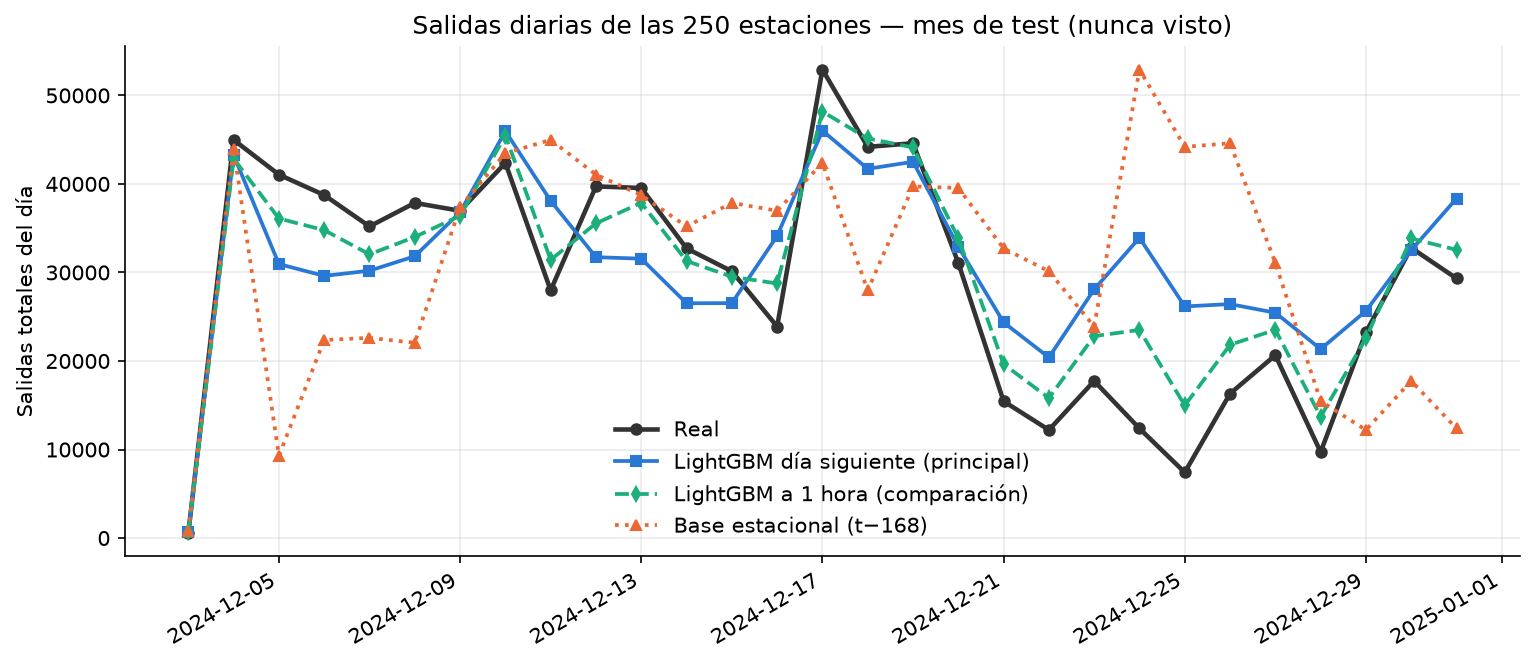

In [4]:
from IPython.display import Image
Image(filename=str(FIGURAS / "02_prediccion_vs_real.png"))

## 2 · Ablación de clima: ¿el clima aporta señal?

Mismo modelo día siguiente, mismos cortes, con y sin las cuatro variables de clima.

In [5]:
abl = pd.DataFrame(res["ablacion_clima_lluvia"]).set_index("condicion")
abl.columns = ["horas_estacion", "base estacional", "sin clima", "con clima", "1 hora"]
abl["mejora_clima_pct"] = ((abl["sin clima"] - abl["con clima"]) / abl["sin clima"] * 100).round(1)
print(f"Mejora relativa del WAPE por añadir clima: test {res['mejoras_wape_pct']['con_clima_vs_sin_clima_test']:+.1f} % · "
      f"CV {res['mejoras_wape_pct']['con_clima_vs_sin_clima_cv']:+.1f} %")
abl

Mejora relativa del WAPE por añadir clima: test +13.1 % · CV +15.0 %


,horas_estacion,base estacional,sin clima,con clima,1 hora,mejora_clima_pct
condicion,,,,,,
Con lluvia,28250,88.55,90.87,61.88,52.16,31.9
Sin lluvia,140000,70.89,54.11,49.16,41.11,9.1
Total,168250,72.86,58.21,50.58,42.34,13.1


In [6]:
# ¿La mejora es consistente día a día o la explica un par de días?
dia = pd.read_csv(REPORTES / "error_por_dia.csv", parse_dates=["fecha"])
dia["mejora_clima"] = dia["WAPE_pred_dia_sin_clima"] - dia["WAPE_pred_dia"]
print(f"Días del test en que el clima reduce el WAPE: {(dia['mejora_clima'] > 0).sum()} de {len(dia)}")
print("Días con mayor mejora por clima:")
dia.nlargest(5, "mejora_clima")[["fecha", "lluvia_mm_dia", "temperatura_media_c", "WAPE_pred_dia_sin_clima", "WAPE_pred_dia", "mejora_clima"]]

Días del test en que el clima reduce el WAPE: 23 de 29
Días con mayor mejora por clima:


,fecha,lluvia_mm_dia,temperatura_media_c,WAPE_pred_dia_sin_clima,WAPE_pred_dia,mejora_clima
18,2024-12-21,0.0,-2.7,140.12,78.12,62.00
22,2024-12-25,0.0,-2.9,327.63,271.02,56.61
25,2024-12-28,5.6,4.0,193.23,139.01,54.22
19,2024-12-22,0.0,-9.1,140.66,88.15,52.51
21,2024-12-24,0.0,-1.7,235.36,189.68,45.68


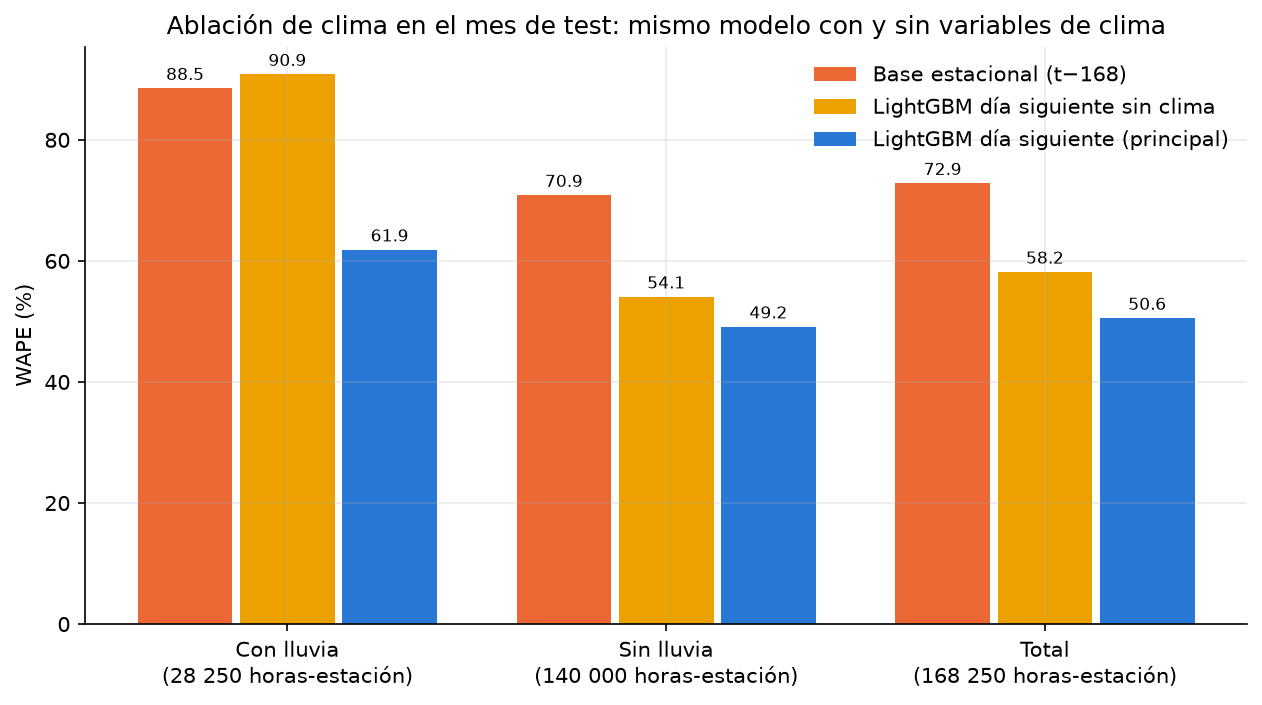

In [7]:
Image(filename=str(FIGURAS / "06_error_lluvia.png"))

## 3 · Importancia de variables con una sola métrica: SHAP

Se usa la **media de |SHAP|** sobre 20 000 horas-estación del test (en unidades de salidas por hora) y su porcentaje del total. Tabla y figura usan la misma métrica (no se mezcla una tabla de *gain* con una figura SHAP).

In [8]:
imp = pd.read_csv(REPORTES / "importancia_shap.csv")
print("Cuota por familia (% de la media de |SHAP|):")
print(pd.DataFrame(res["importancia_shap_por_familia_pct"]).round(1))
imp[imp["modelo"] == "dia_siguiente"].head(12)[["nombre", "familia", "media_abs_shap", "pct"]]

Cuota por familia (% de la media de |SHAP|):
                     dia_siguiente  una_hora
Calendario                    20.0      21.2
Clima                         24.6      12.8
Estación                       6.9       4.3
Historia de demanda           48.5      61.7


,nombre,familia,media_abs_shap,pct
0,Temperatura (°C),Clima,1.5836,17.36
1,Rezago 168 h (semana),Historia de demanda,1.4488,15.88
2,Rezago 24 h (ayer),Historia de demanda,1.4386,15.77
3,Hora del día,Calendario,1.2415,13.61
4,Rezago 336 h (2 semanas),Historia de demanda,1.1951,13.10
5,Estación,Estación,0.6329,6.94
6,Precipitación (mm),Clima,0.5447,5.97
7,Día de semana,Calendario,0.2830,3.10
8,Rezago 48 h (anteayer),Historia de demanda,0.1475,1.62
9,Fin de semana,Calendario,0.1363,1.49


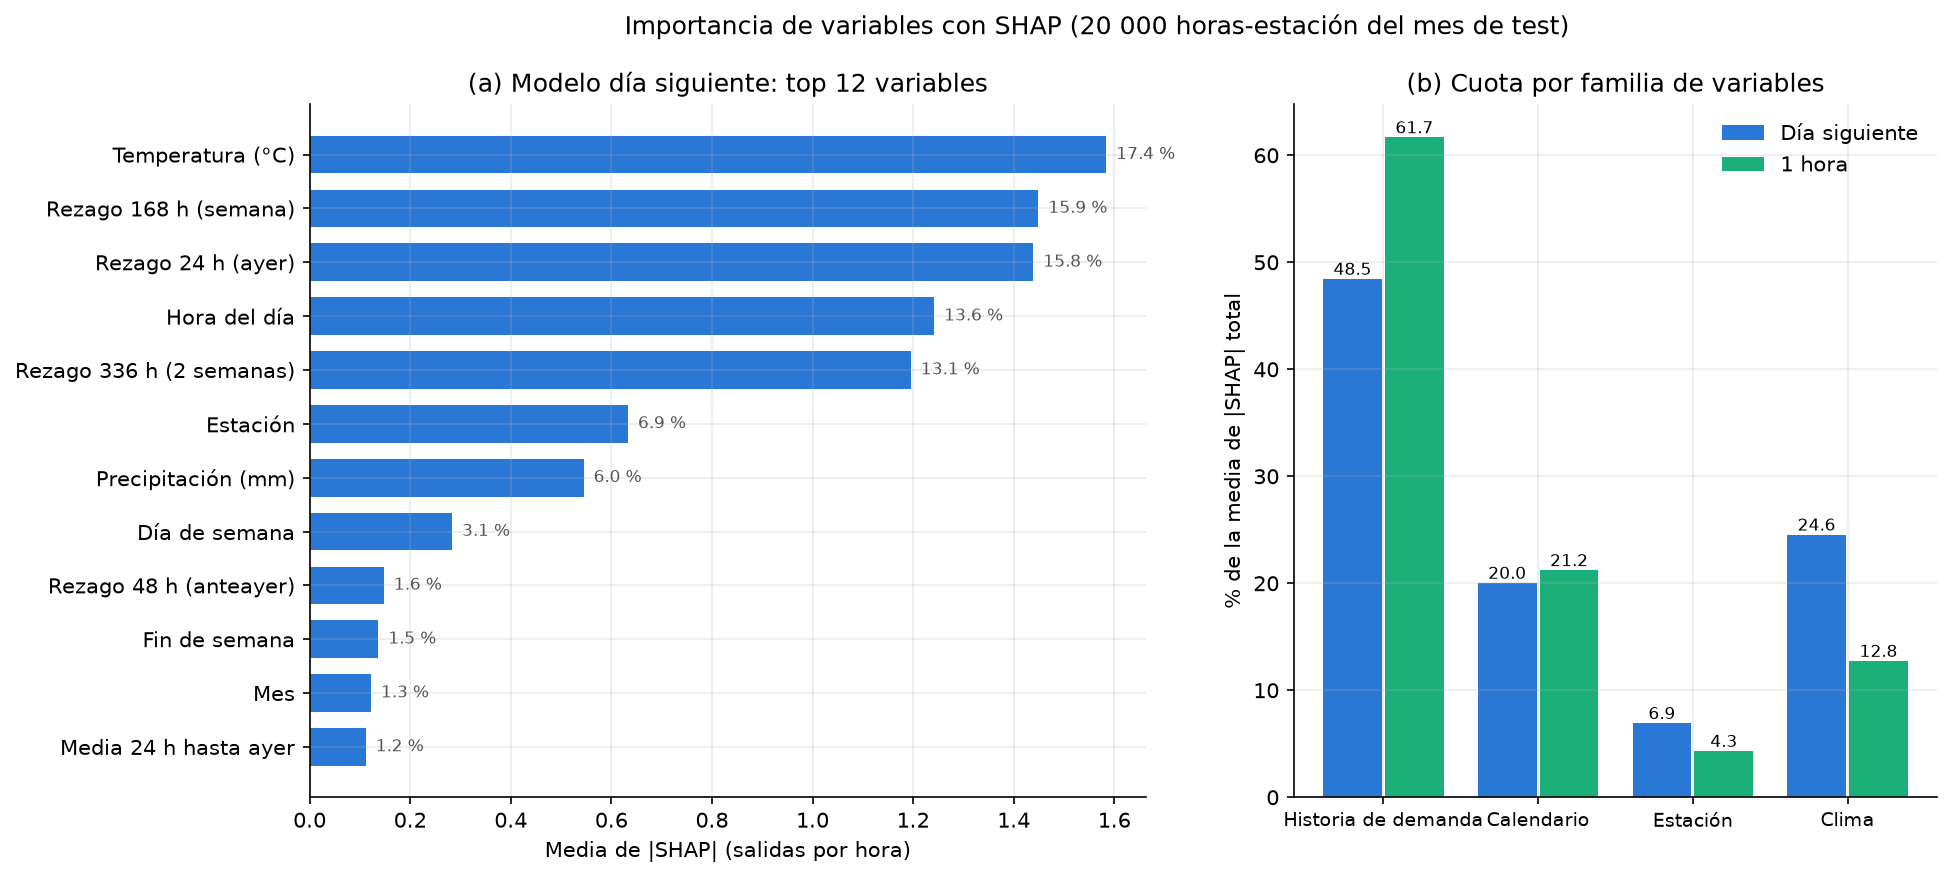

In [9]:
Image(filename=str(FIGURAS / "03_importancia_variables.png"))

SHAP mide cuánto mueve cada variable la predicción, no cuánto mejora el error: una variable puede tener una cuota de SHAP pequeña y aun así mejorar el pronóstico en las horas en que importa (por ejemplo, cuando llueve). Por eso la pregunta "¿aporta el clima?" se responde con la **ablación**, y SHAP se usa para entender *cómo* decide el modelo.

## 4 · Error por hora e intervalos

In [10]:
eh = pd.read_csv(REPORTES / "error_por_hora.csv")
eh.pivot(index="hora", columns="modelo", values="WAPE_pct").round(1).T

hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
modelo,,,,,,,,,,,,,,,,,,,,,,,,
base_estacional,100.5,118.5,133.9,151.0,140.2,95.6,79.0,72.5,73.3,70.6,68.4,66.9,69.1,71.6,72.7,68.6,69.6,68.1,64.5,68.1,77.2,81.1,83.2,89.7
pred_1h,71.2,86.6,103.5,125.3,122.4,83.4,56.9,45.3,40.9,37.4,39.4,39.0,39.5,40.3,37.4,34.4,34.4,36.9,38.8,38.6,45.7,50.8,54.8,61.8
pred_dia,77.6,94.8,108.4,131.1,122.8,78.6,60.8,53.2,52.7,47.3,45.0,44.5,45.3,46.7,45.1,42.4,42.8,44.8,50.4,50.0,57.5,60.3,61.2,68.2


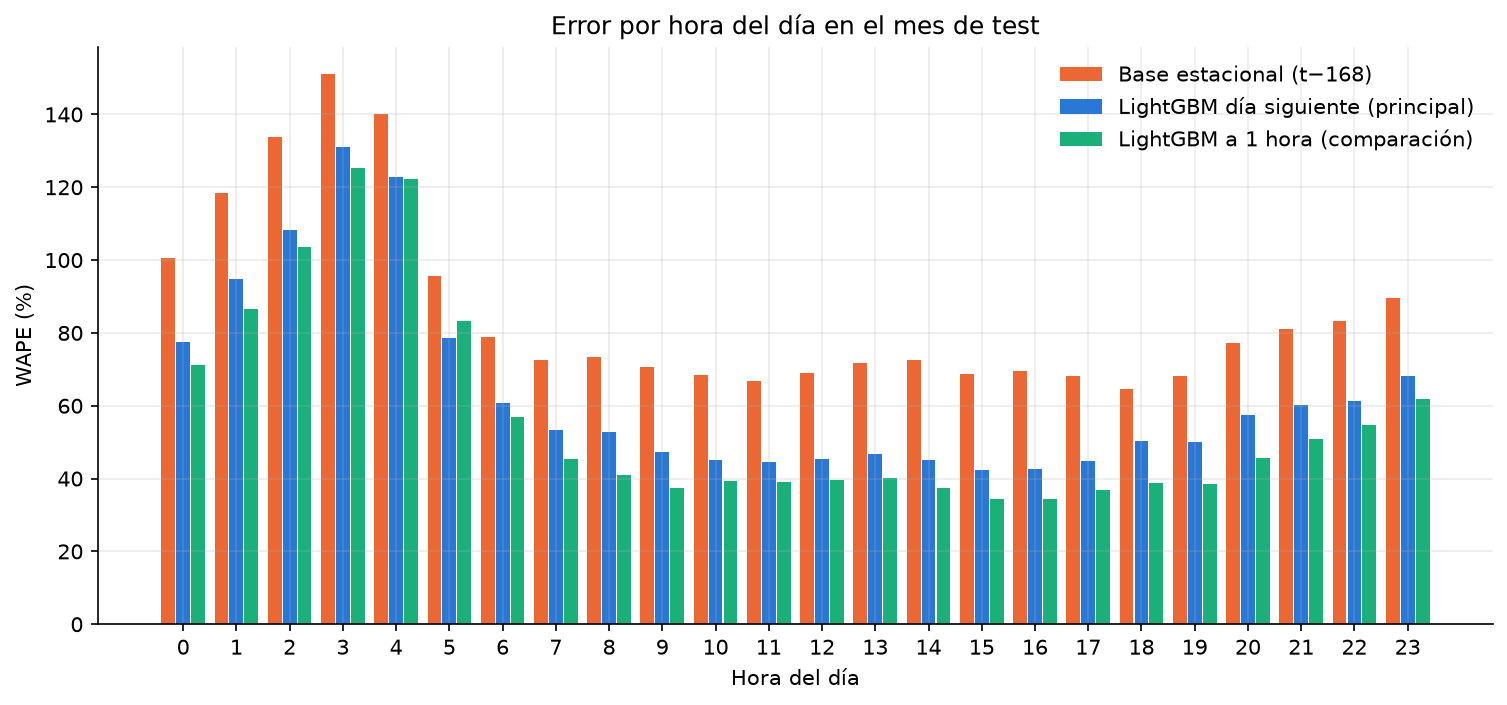

In [11]:
Image(filename=str(FIGURAS / "04_error_por_hora.png"))

Cobertura real del intervalo p10–p90: 75.1 % (nominal 80 %)
Por debajo de p10: 10.9 % (nominal 10 %)
Por encima de p90: 14.0 % (nominal 10 %)


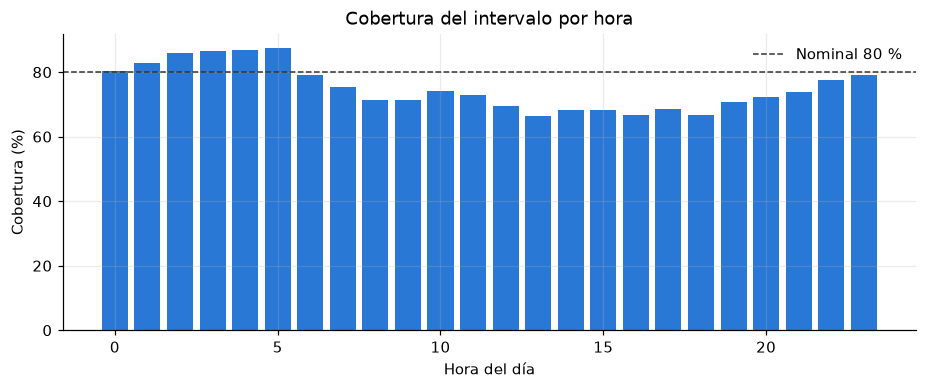

In [12]:
dentro = (pred["salidas"] >= pred["pred_q10"]) & (pred["salidas"] <= pred["pred_q90"])
print(f"Cobertura real del intervalo p10–p90: {dentro.mean() * 100:.1f} % (nominal 80 %)")
print(f"Por debajo de p10: {(pred['salidas'] < pred['pred_q10']).mean() * 100:.1f} % (nominal 10 %)")
print(f"Por encima de p90: {(pred['salidas'] > pred['pred_q90']).mean() * 100:.1f} % (nominal 10 %)")
cob_h = dentro.groupby(pred["hora"]).mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(cob_h.index, cob_h.values, color=AZUL)
ax.axhline(80, color=GRIS, linestyle="--", linewidth=1, label="Nominal 80 %")
ax.set_xlabel("Hora del día"); ax.set_ylabel("Cobertura (%)"); ax.set_title("Cobertura del intervalo por hora")
ax.legend(frameon=False)
plt.show()

## 5 · Errores por estación

`reports/error_por_estacion.csv` tiene el error de cada estación; la app de Streamlit lo muestra en un mapa.

In [13]:
est = pd.read_csv(REPORTES / "error_por_estacion.csv", dtype={"estacion": str})
print(f"WAPE por estación: mediana {est['WAPE_pct'].median():.1f} %, p10 {est['WAPE_pct'].quantile(0.1):.1f} %, p90 {est['WAPE_pct'].quantile(0.9):.1f} %")
sin = est[est["WAPE_pct"].isna()]
print(f"Estaciones sin ninguna salida en el test (WAPE no definido): {len(sin)} -> {', '.join(sin['nombre'])}")
con = est.dropna(subset=["WAPE_pct"])
print(f"Estaciones donde el modelo gana a la base estacional: {(con['WAPE_pct'] < con['WAPE_base_pct']).sum()} de {len(con)} con salidas")
est = con
print(f"Correlación (Spearman) volumen – WAPE: {est['salidas'].corr(est['WAPE_pct'], method='spearman'):.2f}")
est.head(8)[["nombre", "salidas", "WAPE_pct", "WAPE_base_pct", "sesgo_pct"]]

WAPE por estación: mediana 51.2 %, p10 44.1 %, p90 60.1 %
Estaciones sin ninguna salida en el test (WAPE no definido): 3 -> Estación 6432.10, 1 Ave & E 62 St, Broadway & W 51 St
Estaciones donde el modelo gana a la base estacional: 247 de 247 con salidas


Correlación (Spearman) volumen – WAPE: -0.77


,nombre,salidas,WAPE_pct,WAPE_base_pct,sesgo_pct
0,W 34 St & 11 Ave,1540,77.49,99.94,13.93
1,Broadway & W 56 St,2192,75.46,82.76,46.92
2,River Ter & Warren St,1721,75.45,95.06,23.57
3,W 20 St & 10 Ave,2086,74.92,82.89,44.75
4,Greenwich St & W Houston St,2282,71.80,91.10,22.55
5,Pier 40 - Hudson River Park,1876,70.01,93.92,18.04
6,7 Ave & W 55 St,2215,67.55,93.63,18.70
7,10 Ave & W 14 St,2228,65.86,97.31,11.39


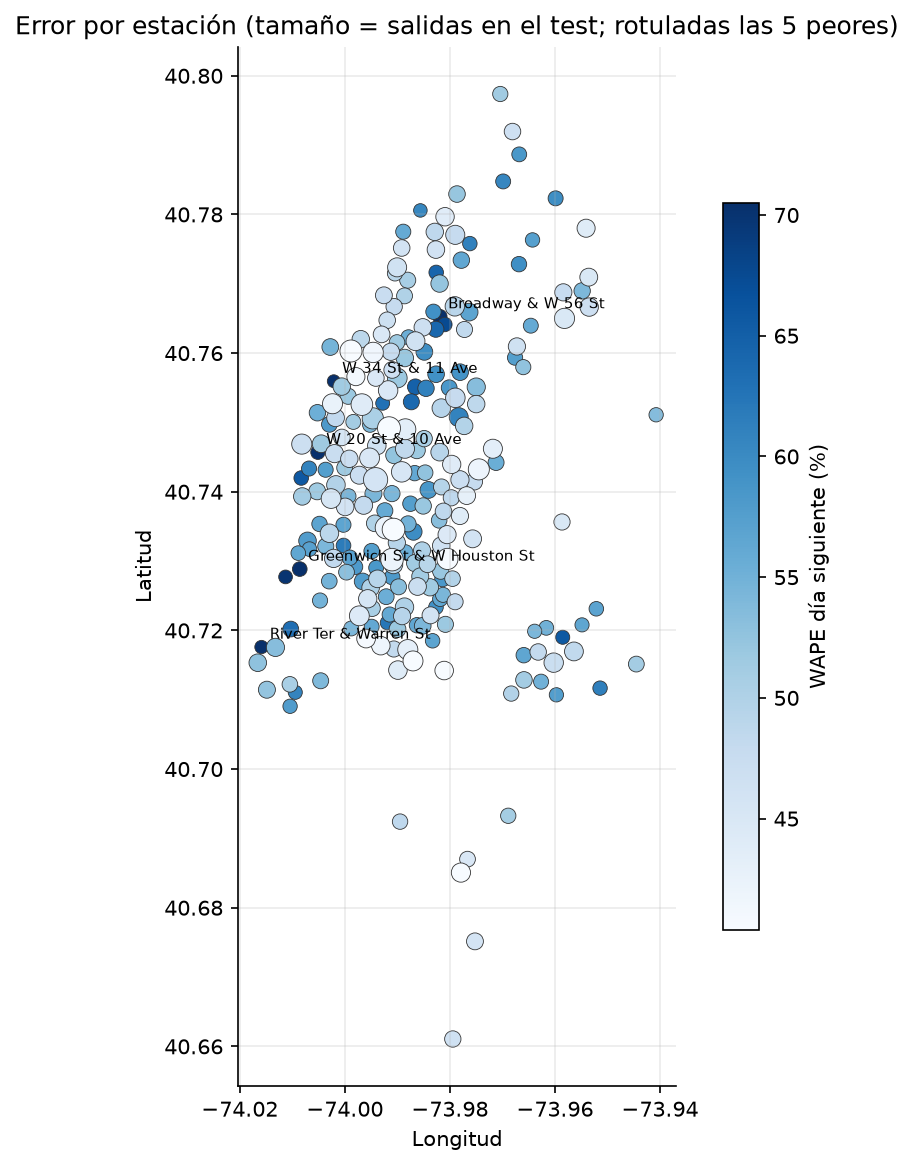

In [14]:
Image(filename=str(FIGURAS / "08_error_por_estacion.png"))

## 6 · Errores por día: feriados y eventos

In [15]:
print("Los 6 días con más error del modelo día siguiente:")
dia.nlargest(6, "WAPE_pred_dia")[["fecha", "es_feriado", "lluvia_mm_dia", "temperatura_media_c", "salidas", "WAPE_pred_dia", "sesgo_pred_dia_pct", "WAPE_base_estacional"]]

Los 6 días con más error del modelo día siguiente:


,fecha,es_feriado,lluvia_mm_dia,temperatura_media_c,salidas,WAPE_pred_dia,sesgo_pred_dia_pct,WAPE_base_estacional
22,2024-12-25,1,0.0,-2.9,7414,271.02,252.90,512.49
21,2024-12-24,0,0.0,-1.7,12377,189.68,174.02,338.12
25,2024-12-28,0,5.6,4.0,9719,139.01,119.65,108.20
23,2024-12-26,0,0.0,-5.0,16313,90.61,61.99,184.97
20,2024-12-23,0,0.0,-10.2,17743,88.92,58.29,89.13
19,2024-12-22,0,0.0,-9.1,12211,88.15,67.08,166.71


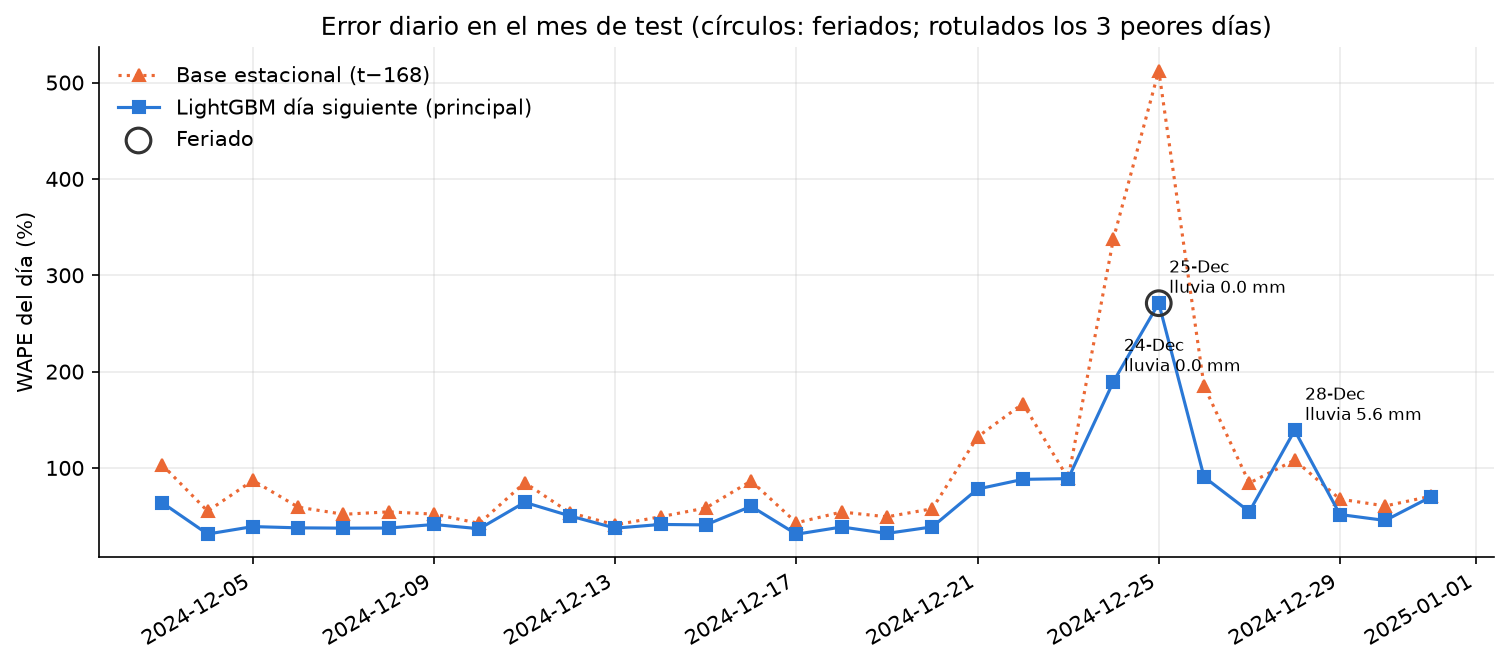

In [16]:
Image(filename=str(FIGURAS / "09_error_por_dia.png"))

## 7 · Residuos

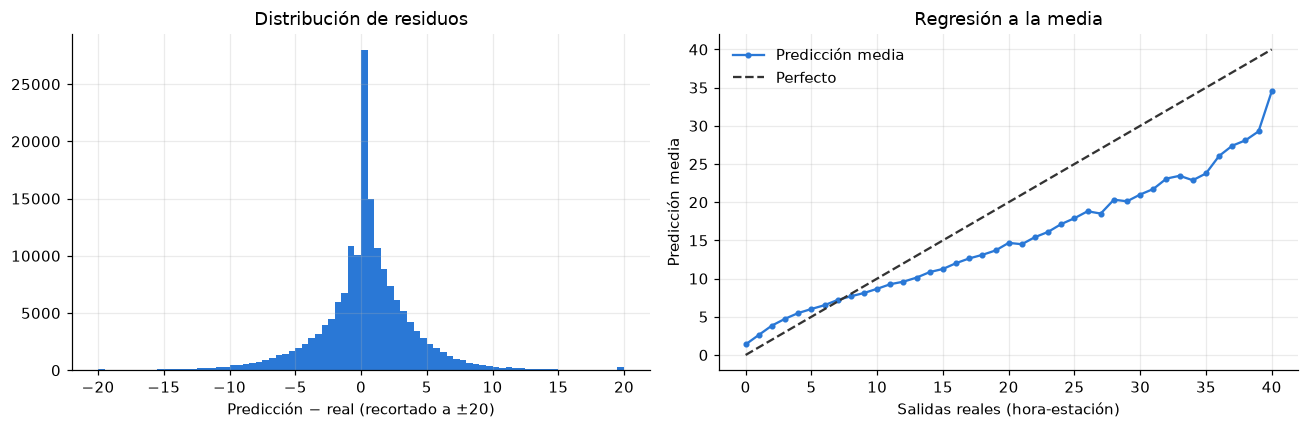

Predicciones negativas antes de recortar a 0 (%): {'pred_dia': 2.61, 'pred_dia_sin_clima': 0.63, 'pred_1h': 1.78}


In [17]:
resid = pred["pred_dia"] - pred["salidas"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(resid.clip(-20, 20), bins=80, color=AZUL)
axes[0].set_xlabel("Predicción − real (recortado a ±20)"); axes[0].set_title("Distribución de residuos")
media = pred.groupby(pred["salidas"].clip(upper=40))["pred_dia"].mean()
axes[1].plot(media.index, media.values, color=AZUL, marker="o", markersize=3, label="Predicción media")
axes[1].plot([0, 40], [0, 40], color=GRIS, linestyle="--", label="Perfecto")
axes[1].set_xlabel("Salidas reales (hora-estación)"); axes[1].set_ylabel("Predicción media"); axes[1].set_title("Regresión a la media")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print("Predicciones negativas antes de recortar a 0 (%):", res["predicciones_negativas_antes_de_recortar_pct"])

El modelo, entrenado con pérdida L2, tiende a la media: sobreestima las horas tranquilas y subestima las horas pico. Esto importa para el rebalanceo (notebook 04): si las alertas se disparan con la predicción media, muchos picos quedan por debajo del umbral. Las predicciones negativas del regresor se recortan a 0 en el pipeline, la API y la app.